# Baseline: Gene Function Prediction with Perturb-Seqr Data

Predict Gene Ontology Biological Process annotations using gene perturbation signatures from [Perturb-Seqr](https://perturbseqr.maayanlab.cloud/). Naive baseline using PCA → feature selection → RandomForest → cross-validated AUROC.

**Labels:** GO Biological Process 2023 from Enrichr (5,407 terms).

In [1]:
%matplotlib inline
# Imports
## Data processing
import pandas as pd
import numpy as np
import scipy as sp
import gzip
import warnings
from maayanlab_bioinformatics.parse import gmt_read_iter
from maayanlab_bioinformatics.harmonization.homologs import mouse_human_homologs
import requests
from pathlib import Path
from collections import defaultdict, Counter
from typing import NamedTuple, Callable
## Machine Learning
import sklearn as sk
from sklearn import (
    preprocessing, decomposition, ensemble, model_selection, pipeline,
    metrics, manifold, feature_selection, linear_model, tree, svm, calibration,
)
## Plotting
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib_venn import venn2
from matplotlib_venn.layout.venn2 import DefaultLayoutAlgorithm
## Utility
import re
import json
from IPython.display import display

# Paths
PERTURBSEQR_ROOT = Path.cwd().parent  # notebook lives in PerturbSeqr/predict/
PREDICT_DIR = PERTURBSEQR_ROOT / "predict"
GMT_DIR = PERTURBSEQR_ROOT / "db" / "data" / "gene_perturbation"
DATA_DIR = PREDICT_DIR / "data"

# Configuration
rng = 2018
N_TARGETS = 10  # number of top GO terms to evaluate (combined matrix is large; increase for full runs)
SKIP_DATASETS = {"cm4ai"}  # empty

## Utility Functions: Feature Construction

In [ ]:
def parse_perturbseqr_signatures(
    gmt_file: Path,
    trainable_items: set[str] | None = None,
    normalize_pert: Callable[[str], str] = str.lower,
    normalize_gene: Callable[[str], str] = lambda g: g,
) -> tuple[defaultdict[str, set[str]], defaultdict[str, set[str]]]:
    up: defaultdict[str, set[str]] = defaultdict(set)
    down: defaultdict[str, set[str]] = defaultdict(set)
    with gzip.open(gmt_file, "rt") as gmt_stream:
        for term, geneset in gmt_read_iter(gmt_stream):
            term = term.split("\t", 1)[0]
            term_lower = term.lower()
            if term_lower.endswith(" up"):
                direction = "up"
            elif term_lower.endswith((" down", " dn")):
                direction = "down"
            else:
                continue
            pert = normalize_pert(term.split("::")[0].strip())
            if trainable_items is not None and pert not in trainable_items:
                continue
            (up if direction == "up" else down)[pert].update(normalize_gene(g) for g in geneset.keys())
    return up, down

def build_feature_matrix(
    gmt_path: Path,
    trainable_items: set[str] | None = None,
    skip_datasets: set[str] | None = None,
    normalize_pert: Callable[[str], str] = str.lower,
    normalize_gene: Callable[[str], str] = lambda g: g,
) -> pd.DataFrame | None:
    """Build item × gene up/down binary matrix from a GMT file or directory of GMTs.
    Returns a DataFrame with rows = items, columns = [GENE_up..., GENE_down...].
    """
    skip_datasets = skip_datasets or set()
    up_all: defaultdict[str, set[str]] = defaultdict(set)
    down_all: defaultdict[str, set[str]] = defaultdict(set)

    gmt_files = sorted(gmt_path.glob("*.gmt.gz")) if gmt_path.is_dir() else [gmt_path]
    for gmt_file in gmt_files:
        if gmt_file.stem.replace(".gmt", "") in skip_datasets:
            continue
        up, down = parse_perturbseqr_signatures(gmt_file, trainable_items, normalize_pert, normalize_gene)
        for k, v in up.items():
            up_all[k].update(v)
        for k, v in down.items():
            down_all[k].update(v)

    items = sorted(set(up_all) | set(down_all))
    if not items:
        return None
    all_genes = sorted({g for d in (up_all, down_all) for genes in d.values() for g in genes})
    cols = [f"{g}_up" for g in all_genes] + [f"{g}_down" for g in all_genes]

    rows = []
    for item in items:
        row = [1 if g in up_all.get(item, set()) else 0 for g in all_genes] + \
              [1 if g in down_all.get(item, set()) else 0 for g in all_genes]
        rows.append(row)
    return pd.DataFrame(rows, index=items, columns=cols, dtype=np.int8)


## Utility Functions: Target Construction

In [3]:
def build_target(go_genes_set: set[str], X: pd.DataFrame) -> np.ndarray:
    return np.array([1 if g in go_genes_set else 0 for g in X.index], dtype=np.int8)

## Utility Functions: Model and Cross-Validation

`build_pipeline` is the pipeline definition (PCA → LinearSVC L1 feature selection → RandomForest → CalibratedClassifierCV) used by both `cv_auroc` and the standalone fit in the single-target demo.

In [ ]:
def build_pipeline(
    cv,
    n_components: int = 64,
    random_state: int = 2018,
) -> sk.calibration.CalibratedClassifierCV:
    return sk.calibration.CalibratedClassifierCV(
        sk.pipeline.Pipeline([
            ('reduce_dim', sk.decomposition.PCA(n_components=n_components, random_state=random_state)),
            ('feature_selection', sk.feature_selection.SelectFromModel(
                sk.svm.LinearSVC(loss="squared_hinge", penalty="l1", dual=False, max_iter=5000))),
            ('clf', sk.ensemble.RandomForestClassifier(random_state=random_state)),
        ]),
        cv=cv,
    )

def plot_cv_roc(
    fold_predictions: list[tuple[np.ndarray, np.ndarray, float]],
    mean_auroc: float,
    std_auroc: float,
    title: str | None = None,
) -> None:
    """plotting cross-validated ROC curve"""
    fig, ax = plt.subplots()
    tprs = []
    mean_fpr = np.linspace(0, 1, 100)
    for fold, (y_test, y_prob, fold_auc) in enumerate(fold_predictions):
        fpr, tpr, _ = sk.metrics.roc_curve(y_test, y_prob)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        ax.plot(fpr, tpr, alpha=0.4, label=f'ROC Fold {fold} (AUC={fold_auc:.3f})')
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    ax.plot(mean_fpr, mean_tpr, color='b', lw=2, alpha=.8,
            label=fr'Mean ROC (AUC = {mean_auroc:.2f} $\pm$ {std_auroc:.2f})')
    std_tpr = np.std(tprs, axis=0)
    ax.fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0),
                    np.minimum(mean_tpr + std_tpr, 1), color='grey', alpha=.2)
    ax.plot([0, 1], [0, 1], '--', label='Luck')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    if title:
        ax.set_title(title)
    ax.legend(loc='lower right')
    plt.tight_layout()

class CVResult(NamedTuple):
    mean_auroc: float
    std_auroc: float
    fold_aurocs: list[float]
    oof_predictions: np.ndarray  # out-of-fold predict_proba for each row in X

def cv_auroc(
    X_vals: np.ndarray,
    y: np.ndarray,
    n_splits: int = 3,
    n_components: int = 64,
    random_state: int = 2018,
    *,
    plot: bool = False,
    plot_title: str | None = None,
) -> CVResult:
    """Stratified k-fold CV with PCA → LinearSVC L1 feature selection → RandomForest → CalibratedClassifierCV.

    Returns CVResult(mean_auroc, std_auroc, fold_aurocs, oof_predictions).

    When plot=True, also renders the cross-validated ROC curve as a side effect.
    """
    # Cap n_components considering smaller datasets may have very few training samples in each fold and PCA can't have more components than samples - 1.
    inner_train_size = int(X_vals.shape[0] * ((n_splits - 1) / n_splits) ** 2)
    n_comp = min(n_components, inner_train_size - 1, X_vals.shape[1])
    cv = sk.model_selection.StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    model = build_pipeline(cv, n_components=n_comp, random_state=random_state)
    fold_aurocs = []
    fold_predictions = [] if plot else None
    oof_predictions = np.zeros(len(y), dtype=np.float64)
    for train_idx, test_idx in cv.split(X_vals, y):
        model.fit(X_vals[train_idx], y[train_idx])
        y_prob = model.predict_proba(X_vals[test_idx])[:, 1]
        fold_auc = sk.metrics.roc_auc_score(y[test_idx], y_prob)
        fold_aurocs.append(fold_auc)
        oof_predictions[test_idx] = y_prob
        if plot:
            fold_predictions.append((y[test_idx], y_prob, fold_auc))
    mean_auroc = float(np.mean(fold_aurocs))
    std_auroc = float(np.std(fold_aurocs))
    if plot:
        plot_cv_roc(fold_predictions, mean_auroc, std_auroc, title=plot_title)
    return CVResult(mean_auroc, std_auroc, fold_aurocs, oof_predictions)

def summarize_aurocs(df: pd.DataFrame, auroc_col: str = "auroc") -> dict:
    """Compute summary statistics"""
    s = df[auroc_col].dropna()
    return {
        "n": len(s),
        "mean": float(s.mean()),
        "median": float(s.median()),
        "max": float(s.max()),
        "above_0.6": int((s > 0.6).sum()),
        "above_0.7": int((s > 0.7).sum()),
    }

def evaluate_targets(
    X: pd.DataFrame,
    target_builder: Callable,
    targets: list[tuple],
    min_pos: int = 10,
    label_field: str | None = None,
    verbose: bool = True,
) -> pd.DataFrame:
    """Run cv_auroc for each target and return a results DataFrame"""
    results = []
    for target_arg, metadata in targets:
        y = target_builder(target_arg, X)
        n_pos = int(y.sum())
        if n_pos < min_pos or n_pos > len(y) - min_pos:
            continue
        try:
            auroc = cv_auroc(X.values, y).mean_auroc
        except Exception:
            auroc = np.nan
        results.append({**metadata, "n_positive": n_pos, "auroc": auroc})
        if verbose:
            label = metadata.get(label_field, "?") if label_field else next(iter(metadata.values()))
            print(f"  {label}: AUROC={auroc:.3f} (n={n_pos})")
    return pd.DataFrame(results)

## Inputs

Load the GO BP annotations from Enrichr (cached locally) and select a GO term to predict in the single-target demo.

In [ ]:
# Download / load GO Biological Process 2023 from Enrichr
GO_CACHE = DATA_DIR / "go_bp_2023.json"
if GO_CACHE.exists():
    go_terms = json.load(open(GO_CACHE))
    print(f"Loaded cached GO BP: {len(go_terms)} terms")
else:
    resp = requests.get("https://maayanlab.cloud/Enrichr/geneSetLibrary?mode=text&libraryName=GO_Biological_Process_2023", timeout=60)
    go_terms = {}
    for line in resp.text.strip().split("\n"):
        parts = line.split("\t")
        go_terms[parts[0]] = [g.strip().upper() for g in parts[2:] if g.strip()]
    json.dump(go_terms, open(GO_CACHE, "w"))
    print(f"Downloaded GO BP: {len(go_terms)} terms, cached to {GO_CACHE}")

go_gene_set = set(g for genes in go_terms.values() for g in genes)

# Single-target demo: Regulation of Apoptotic Process
TARGET_GO = "Regulation Of Apoptotic Process (GO:0042981)"
TARGET_GO_GENES = set(go_terms[TARGET_GO])

print(f"Total GO BP terms: {len(go_terms):,}")
print(f"Total unique GO genes: {len(go_gene_set):,}")
print(f"Median genes per term: {np.median([len(g) for g in go_terms.values()]):.0f}")
print(f"\nTarget: {TARGET_GO}")
print(f"GO term gene count: {len(TARGET_GO_GENES)}")

# Mouse->human ortholog map (MGI), used as the gene-symbol normalizer for perturbation parsing.
m2h_df = mouse_human_homologs(uppercase=True)
human_symbols = set(m2h_df["human"])
mouse_only_df = m2h_df[~m2h_df["mouse"].isin(human_symbols)]
mouse_to_human = dict(zip(mouse_only_df["mouse"], mouse_only_df["human"]))

def to_human(symbol: str) -> str:
    """Uppercase a gene symbol and map mouse-only ortholog to its human equivalent."""
    s = symbol.upper()
    return mouse_to_human.get(s, s)

print(f"\nMouse-only -> human ortholog map: {len(mouse_to_human):,} entries")


Loaded cached GO BP: 5407 terms
Total GO BP terms: 5,407
Total unique GO genes: 14,698
Median genes per term: 15

Target: Regulation Of Apoptotic Process (GO:0042981)
GO term gene count: 705

Mouse-only -> human ortholog map: 3,290 entries


## Trainable Feature Overlap

In [6]:
per_dataset_genes = {}
all_perturbed_genes: set[str] = set()
for gmt_file in sorted(GMT_DIR.glob("*.gmt.gz")):
    ds = gmt_file.stem.replace(".gmt", "")
    if ds in SKIP_DATASETS:
        continue
    up, down = parse_perturbseqr_signatures(gmt_file, normalize_pert=to_human, normalize_gene=to_human)
    genes = set(up) | set(down)
    per_dataset_genes[ds] = genes
    all_perturbed_genes.update(genes)
    print(f"{ds}: {len(genes):,} unique perturbed genes")

trainable = all_perturbed_genes & go_gene_set
print(f"\nTotal Perturb-Seqr perturbed genes: {len(all_perturbed_genes):,}")
print(f"GO BP annotated genes: {len(go_gene_set):,}")
print(f"Trainable (overlap): {len(trainable):,}")


creeds-gene: 970 unique perturbed genes
lincs-l1000-xpr: 6,962 unique perturbed genes
perturb-atlas-human: 2,611 unique perturbed genes
perturb-atlas-mouse: 2,400 unique perturbed genes
replogle-perturb-seq: 3,098 unique perturbed genes
rummageo-gene: 1,001 unique perturbed genes

Total Perturb-Seqr perturbed genes: 12,388
GO BP annotated genes: 14,698
Trainable (overlap): 7,465


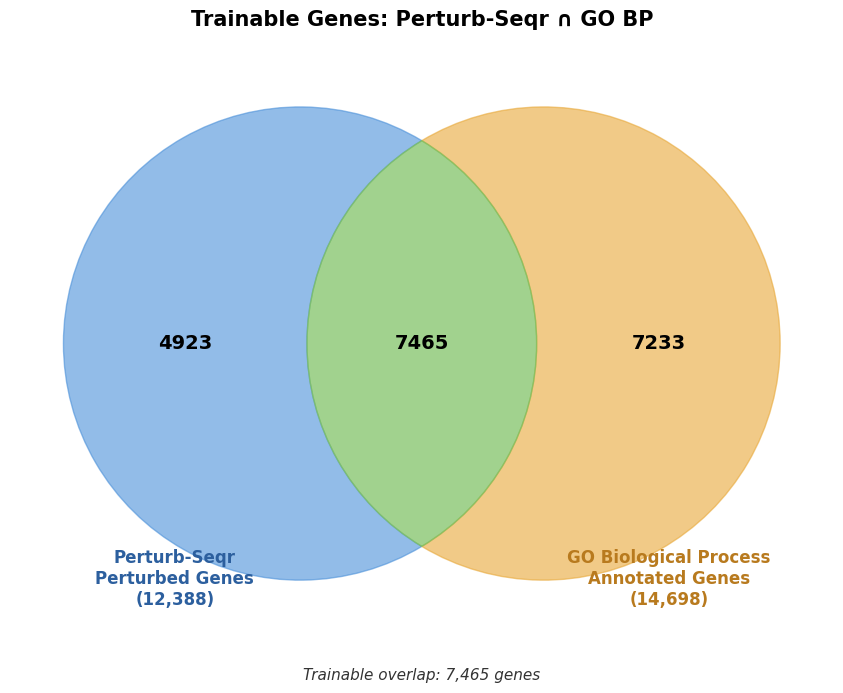

In [7]:
# Venn diagram: Perturb-Seqr perturbed genes vs GO BP annotated genes
fig, ax = plt.subplots(figsize=(10, 7))

v = venn2(
    [all_perturbed_genes, go_gene_set],
    set_labels=("", ""),
    layout_algorithm=DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 0.6)),
    ax=ax,
)
v.get_patch_by_id("10").set_color("#4A90D9")
v.get_patch_by_id("10").set_alpha(0.6)
v.get_patch_by_id("01").set_color("#E8A838")
v.get_patch_by_id("01").set_alpha(0.6)
v.get_patch_by_id("11").set_color("#7ABF5E")
v.get_patch_by_id("11").set_alpha(0.7)
for label_id in ["10", "01", "11"]:
    v.get_label_by_id(label_id).set_fontsize(14)
    v.get_label_by_id(label_id).set_fontweight("bold")

ax.text(0.2, 0.05, f"Perturb-Seqr\nPerturbed Genes\n({len(all_perturbed_genes):,})",
        ha="center", fontsize=12, fontweight="bold", color="#2C5F9E", transform=ax.transAxes)
ax.text(0.8, 0.05, f"GO Biological Process\nAnnotated Genes\n({len(go_gene_set):,})",
        ha="center", fontsize=12, fontweight="bold", color="#B87A1E", transform=ax.transAxes)
ax.set_title("Trainable Genes: Perturb-Seqr ∩ GO BP", fontsize=15, fontweight="bold", pad=20)
ax.text(0.5, -0.08, f"Trainable overlap: {len(trainable):,} genes",
        ha="center", fontsize=11, style="italic", color="#333", transform=ax.transAxes)

plt.tight_layout()
plt.savefig(DATA_DIR / "gene_function_venn.png", dpi=150, bbox_inches="tight")
plt.show()

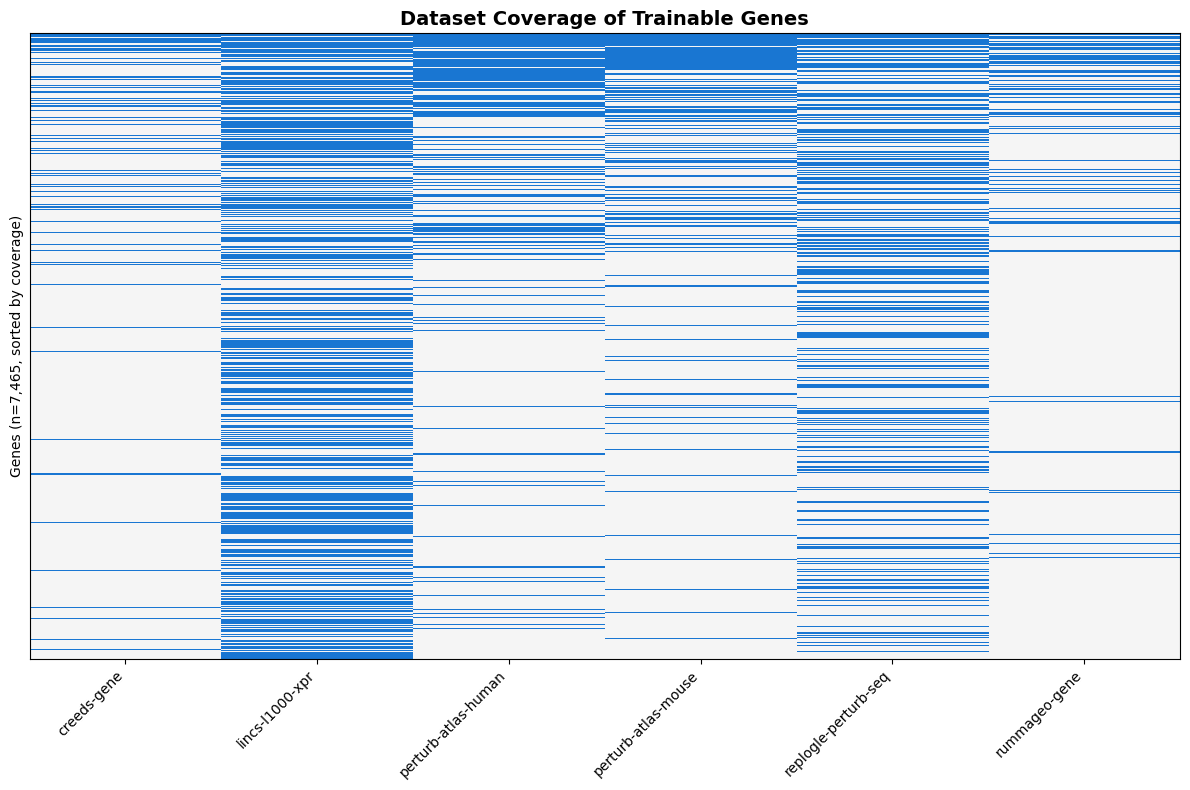


Datasets per trainable gene:
  1 dataset(s): 4,795 genes
  2 dataset(s): 1,661 genes
  3 dataset(s): 603 genes
  4 dataset(s): 252 genes
  5 dataset(s): 130 genes
  6 dataset(s): 24 genes


In [8]:
# Per-dataset coverage heatmap (gene × dataset binary matrix)
datasets_sorted = sorted(per_dataset_genes.keys())
coverage = pd.DataFrame(
    {ds: [1 if g in per_dataset_genes[ds] else 0 for g in sorted(trainable)] for ds in datasets_sorted},
    index=sorted(trainable),
)
coverage["total"] = coverage.sum(axis=1)
coverage = coverage.sort_values("total", ascending=False).drop(columns="total")

fig, ax = plt.subplots(figsize=(12, 8))
cmap = LinearSegmentedColormap.from_list("custom", ["#f5f5f5", "#1976D2"])
ax.imshow(coverage.values, aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_xticks(range(len(coverage.columns)))
ax.set_xticklabels(coverage.columns, rotation=45, ha="right", fontsize=10)
ax.set_ylabel(f"Genes (n={len(coverage):,}, sorted by coverage)")
ax.set_yticks([])
ax.set_title("Dataset Coverage of Trainable Genes", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(DATA_DIR / "gene_function_coverage_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

n_ds = coverage.sum(axis=1)
print(f"\nDatasets per trainable gene:")
for i in range(1, int(n_ds.max()) + 1):
    count = (n_ds == i).sum()
    if count > 0:
        print(f"  {i} dataset(s): {count:,} genes")

## Combined Feature Matrix

Build a single perturbed-gene × responding-gene up/down binary matrix combining all datasets (excluding skipped ones).

In [9]:
X = build_feature_matrix(GMT_DIR, trainable_items=trainable, skip_datasets=SKIP_DATASETS, normalize_pert=to_human, normalize_gene=to_human)
print(f"X shape: {X.shape} (perturbed genes × responding gene-direction features)")
print(f"Sparsity: {100*(1 - X.values.sum()/np.prod(X.shape)):.1f}%")
print(f"Mean features per gene: {X.sum(axis=1).mean():.0f}")
display(X.iloc[:5, :8])


X shape: (7465, 56378) (perturbed genes × responding gene-direction features)
Sparsity: 96.9%
Mean features per gene: 1724


,0610005C13RIK_up,0610007P14RIK_up,0610009B22RIK_up,0610009L18RIK_up,0610010B08RIK_up,0610010F05RIK_up,0610010K14RIK_up,0610011F06RIK_up
AAK1,0,0,0,0,0,0,0,0
AARS1,0,0,0,0,0,0,0,0
AASDHPPT,0,0,0,0,0,0,0,0
AATF,0,0,0,0,0,0,0,0
AATK,0,0,0,0,0,0,0,0


## Single GO Term Demo: Regulation of Apoptotic Process

Run the full pipeline on a single target GO term to inspect ROC curve, confusion matrix, and novel predictions. Mirrors the harmonizome-ml `output.ipynb` flow.

In [10]:
# Build target vector for the selected GO term
y = build_target(TARGET_GO_GENES, X)

print(f"Target: {TARGET_GO}")
print(f"Input shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Class balance: {y.sum()} positive ({100*y.mean():.1f}%), {(y==0).sum()} negative ({100*(1-y.mean()):.1f}%)")

Target: Regulation Of Apoptotic Process (GO:0042981)
Input shape: (7465, 56378)
Target shape: (7465,)
Class balance: 506 positive (6.8%), 6959 negative (93.2%)


### ROC Curve

Cross-validated ROC curve. Low fold variance and high AUC indicate a well-generalized model.

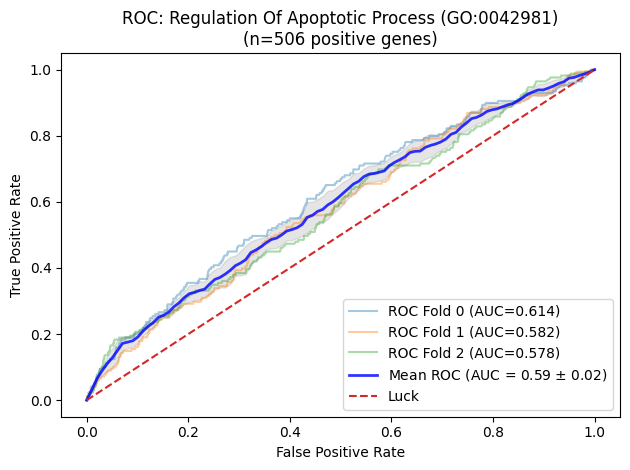

In [ ]:
# Run cv_auroc with plot=True to render the ROC curve.
#  The returned CVResult includes out-of-fold predictions for the confusion matrix and novel predictions table: every prediction is from the CV fold where that gene was held out.
cv_result = cv_auroc(
    X.values, y,
    plot=True,
    plot_title=f"ROC: {TARGET_GO}\n(n={int(y.sum())} positive genes)",
)
mean_auroc, std_auroc, _, oof_predictions = cv_result

In [12]:
# Statistical significance check
z = (mean_auroc - 0.5) / std_auroc if std_auroc > 0 else float("inf")
cl = sp.stats.norm.cdf(z) * 100
ci = sp.stats.norm.interval(0.95, loc=mean_auroc, scale=std_auroc)
print('Confidence interval (95%):', ci)
print("We are %0.3f %% confident the model's results are not just chance." % cl)
if cl > 95:
    print('Statistically significant. These results can be trusted.')
else:
    print('Not statistically significant. These results should not be trusted.')

Confidence interval (95%): (np.float64(0.5594619003919566), np.float64(0.6225458729691445))
We are 100.000 % confident the model's results are not just chance.
Statistically significant. These results can be trusted.


### Confusion Matrix and Novel Predictions

In [13]:
# Confusion matrix using out-of-fold predictions
y_pred_oof = (oof_predictions > 0.5).astype(int)
cm = metrics.confusion_matrix(y, y_pred_oof)
display(cm)
print(f"\n True negatives:  {cm[0,0]}")
print(f" False positives: {cm[0,1]}")
print(f" False negatives: {cm[1,0]}")
print(f" True positives:  {cm[1,1]}")

array([[6959,    0],
       [ 506,    0]])


 True negatives:  6959
 False positives: 0
 False negatives: 506
 True positives:  0


In [14]:
# Uses out-of-fold predictions so each prediction is from a model that never saw that gene
results = pd.DataFrame({
    "Known": y,
    "Predicted": (oof_predictions > 0.5).astype(int),
    "Prediction Probability": oof_predictions,
}, index=X.index)
results.index.name = "Gene"

novel = results[(results["Known"] == 0) & (results["Prediction Probability"] > 0.5)]
print(f"Novel predictions (not annotated, predicted positive): {len(novel)}")
if len(novel) > 0:
    display(novel.sort_values("Prediction Probability", ascending=False).head(20))
else:
    print("No novel predictions above 0.5 threshold; showing top predictions overall:")
    display(results.sort_values("Prediction Probability", ascending=False).head(20))

Novel predictions (not annotated, predicted positive): 0
No novel predictions above 0.5 threshold; showing top predictions overall:


,Known,Predicted,Prediction Probability
Gene,,,
PSAP,0,0,0.258367
ZXDC,0,0,0.246178
PALM,0,0,0.220132
RHOC,0,0,0.214917
ATM,1,0,0.204245
NFE2L2,0,0,0.201425
SYK,0,0,0.193113
PINK1,1,0,0.191870
CCNA2,0,0,0.184644


## Multi-GO Evaluation (Combined Datasets)

Run the classifier across the top N most populated GO terms (with ≥20 trainable positives) and report the per-term AUROC distribution.

In [15]:
# Filter to GO terms with enough trainable positive examples
trainable_set = set(X.index)
go_eval = []
for term, genes in go_terms.items():
    genes_upper = set(g.upper() for g in genes)
    n_pos = len(genes_upper & trainable_set)
    if 20 <= n_pos <= len(trainable_set) - 20:
        go_eval.append((term, genes_upper, n_pos))
go_eval.sort(key=lambda x: -x[2])
go_eval = go_eval[:N_TARGETS]
print(f"Evaluating top {len(go_eval)} GO terms on combined data...\n")

go_targets = [(genes_upper, {"go_term": term}) for term, genes_upper, _ in go_eval]
go_target_builder = lambda gs, X: build_target(gs, X)

combined_df = evaluate_targets(
    X, go_target_builder, go_targets, label_field="go_term",
).sort_values("auroc", ascending=False)

stats = summarize_aurocs(combined_df)
print(f"\nEvaluated {stats['n']} GO terms")
print(f"Mean AUROC: {stats['mean']:.3f}")
print(f"Median AUROC: {stats['median']:.3f}")
display(combined_df)

Evaluating top 10 GO terms on combined data...

  Regulation Of Transcription By RNA Polymerase II (GO:0006357): AUROC=0.745 (n=1315)
  Regulation Of DNA-templated Transcription (GO:0006355): AUROC=0.739 (n=1254)
  Positive Regulation Of DNA-templated Transcription (GO:0045893): AUROC=0.744 (n=935)
  Regulation Of Gene Expression (GO:0010468): AUROC=0.675 (n=775)
  Positive Regulation Of Transcription By RNA Polymerase II (GO:0045944): AUROC=0.762 (n=723)
  Negative Regulation Of DNA-templated Transcription (GO:0045892): AUROC=0.716 (n=687)
  Regulation Of Cell Population Proliferation (GO:0042127): AUROC=0.620 (n=526)
  Regulation Of Apoptotic Process (GO:0042981): AUROC=0.591 (n=506)
  Negative Regulation Of Transcription By RNA Polymerase II (GO:0000122): AUROC=0.717 (n=505)
  Protein Modification Process (GO:0036211): AUROC=0.644 (n=486)

Evaluated 10 GO terms
Mean AUROC: 0.695
Median AUROC: 0.717


,go_term,n_positive,auroc
4,Positive Regulation Of Transcription By RNA Po...,723,0.762162
0,Regulation Of Transcription By RNA Polymerase ...,1315,0.744754
2,Positive Regulation Of DNA-templated Transcrip...,935,0.744058
1,Regulation Of DNA-templated Transcription (GO:...,1254,0.738919
8,Negative Regulation Of Transcription By RNA Po...,505,0.717171
5,Negative Regulation Of DNA-templated Transcrip...,687,0.716212
3,Regulation Of Gene Expression (GO:0010468),775,0.675133
9,Protein Modification Process (GO:0036211),486,0.644297
6,Regulation Of Cell Population Proliferation (G...,526,0.620168
7,Regulation Of Apoptotic Process (GO:0042981),506,0.591004


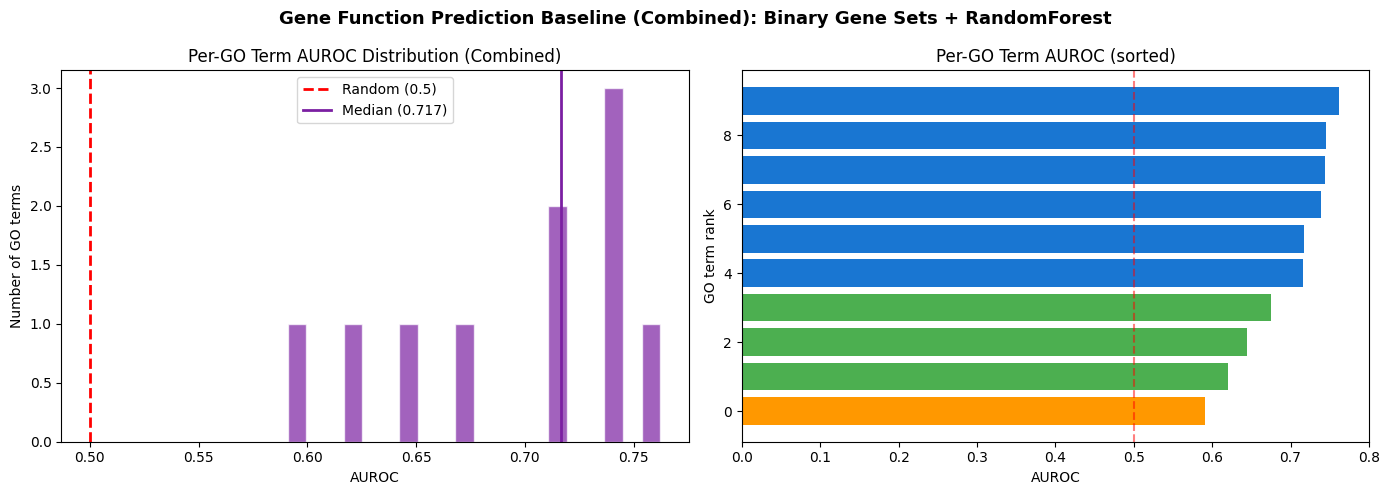


Combined summary:
  GO terms evaluated: 10
  Mean AUROC: 0.695
  Median AUROC: 0.717
  GO terms with AUROC > 0.6: 9
  GO terms with AUROC > 0.7: 6


In [16]:
# Visualize AUROC distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(combined_df["auroc"].dropna(), bins=20, color="#7B1FA2", alpha=0.7, edgecolor="white")
ax1.axvline(x=0.5, color="red", linestyle="--", linewidth=2, label="Random (0.5)")
ax1.axvline(x=combined_df["auroc"].median(), color="#7B1FA2", linestyle="-", linewidth=2,
            label=f"Median ({combined_df['auroc'].median():.3f})")
ax1.set_xlabel("AUROC")
ax1.set_ylabel("Number of GO terms")
ax1.set_title("Per-GO Term AUROC Distribution (Combined)")
ax1.legend()

sorted_combined = combined_df.dropna(subset=["auroc"]).sort_values("auroc")
colors = ["#D32F2F" if x < 0.5 else "#FF9800" if x < 0.6 else "#4CAF50" if x < 0.7 else "#1976D2" for x in sorted_combined["auroc"]]
ax2.barh(range(len(sorted_combined)), sorted_combined["auroc"], color=colors, height=0.8)
ax2.axvline(x=0.5, color="red", linestyle="--", alpha=0.5)
ax2.set_xlabel("AUROC")
ax2.set_ylabel("GO term rank")
ax2.set_title("Per-GO Term AUROC (sorted)")

fig.suptitle("Gene Function Prediction Baseline (Combined): Binary Gene Sets + RandomForest",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DATA_DIR / "gene_function_combined_auroc.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nCombined summary:")
print(f"  GO terms evaluated: {len(combined_df)}")
print(f"  Mean AUROC: {combined_df['auroc'].mean():.3f}")
print(f"  Median AUROC: {combined_df['auroc'].median():.3f}")
print(f"  GO terms with AUROC > 0.6: {(combined_df['auroc'] > 0.6).sum()}")
print(f"  GO terms with AUROC > 0.7: {(combined_df['auroc'] > 0.7).sum()}")

## Per-Dataset Evaluation

Run the same classifier independently on each Perturb-Seqr gene perturbation dataset to compare predictive performance across platforms.

In [17]:
dataset_results = {}
for gmt_file in sorted(GMT_DIR.glob("*.gmt.gz")):
    dataset = gmt_file.stem.replace(".gmt", "")
    if dataset in SKIP_DATASETS:
        continue

    X_ds = build_feature_matrix(gmt_file, trainable_items=trainable, normalize_pert=to_human, normalize_gene=to_human)
    if X_ds is None or len(X_ds) < 30:
        print(f"{dataset}: only {len(X_ds) if X_ds is not None else 0} genes, skipping")
        continue

    print(f"\n{'='*60}")
    print(f"{dataset}: {X_ds.shape[0]} genes × {X_ds.shape[1]} features")
    print(f"{'='*60}")

    df = evaluate_targets(X_ds, go_target_builder, go_targets, verbose=False)
    if len(df) == 0:
        print("  No GO terms with enough positive genes")
        continue
    dataset_results[dataset] = df
    stats = summarize_aurocs(df)
    best = df.loc[df['auroc'].idxmax()]
    print(f"  GO terms evaluated: {stats['n']}")
    print(f"  Mean AUROC: {stats['mean']:.3f}")
    print(f"  Median AUROC: {stats['median']:.3f}")
    print(f"  Best: {best['go_term'][:50]} ({best['auroc']:.3f})")


creeds-gene: 792 genes × 51608 features
  GO terms evaluated: 10
  Mean AUROC: 0.588
  Median AUROC: 0.589
  Best: Regulation Of DNA-templated Transcription (GO:0006 (0.641)

lincs-l1000-xpr: 4116 genes × 21028 features
  GO terms evaluated: 10
  Mean AUROC: 0.530
  Median AUROC: 0.536
  Best: Protein Modification Process (GO:0036211) (0.590)

perturb-atlas-human: 1717 genes × 33870 features
  GO terms evaluated: 10
  Mean AUROC: 0.589
  Median AUROC: 0.618
  Best: Regulation Of Transcription By RNA Polymerase II ( (0.676)

perturb-atlas-mouse: 1511 genes × 31690 features
  GO terms evaluated: 10
  Mean AUROC: 0.590
  Median AUROC: 0.590
  Best: Regulation Of Transcription By RNA Polymerase II ( (0.661)

replogle-perturb-seq: 2666 genes × 18656 features
  GO terms evaluated: 10
  Mean AUROC: 0.604
  Median AUROC: 0.617
  Best: Positive Regulation Of Transcription By RNA Polyme (0.682)

rummageo-gene: 926 genes × 37854 features


/Users/johngardner_mountsinai/work/PerturbSeqr/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


  GO terms evaluated: 10
  Mean AUROC: 0.507
  Median AUROC: 0.507
  Best: Protein Modification Process (GO:0036211) (0.554)


## Per-Dataset Comparison

In [18]:
# Summary table: per-dataset stats + combined row
def _row(dataset_name, trainable_count, df):
    stats = summarize_aurocs(df)
    return {
        "Dataset": dataset_name,
        "Trainable genes": trainable_count,
        "GO terms evaluated": stats["n"],
        "Mean AUROC": stats["mean"],
        "Median AUROC": stats["median"],
        "Max AUROC": stats["max"],
        "> 0.6": stats["above_0.6"],
        "> 0.7": stats["above_0.7"],
    }

summary = [
    _row(ds, len(per_dataset_genes[ds] & trainable), df)
    for ds, df in dataset_results.items()
]
summary.append(_row("ALL COMBINED", len(trainable), combined_df))
summary_df = pd.DataFrame(summary).sort_values("Mean AUROC", ascending=False)
display(summary_df)

,Dataset,Trainable genes,GO terms evaluated,Mean AUROC,Median AUROC,Max AUROC,> 0.6,> 0.7
6,ALL COMBINED,7465,10,0.695388,0.716691,0.762162,9,6
4,replogle-perturb-seq,2666,10,0.603893,0.616508,0.682424,6,0
3,perturb-atlas-mouse,1511,10,0.589969,0.590205,0.660821,4,0
2,perturb-atlas-human,1717,10,0.589093,0.617930,0.675874,6,0
0,creeds-gene,792,10,0.588239,0.588909,0.640683,4,0
1,lincs-l1000-xpr,4116,10,0.529650,0.535861,0.590412,0,0
5,rummageo-gene,926,10,0.506864,0.507176,0.553663,0,0


/var/folders/_j/p5822ycn1cbc1q_bcly_5ft80000gn/T/ipykernel_2571/2502412148.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=datasets_for_plot, patch_artist=True, vert=True)


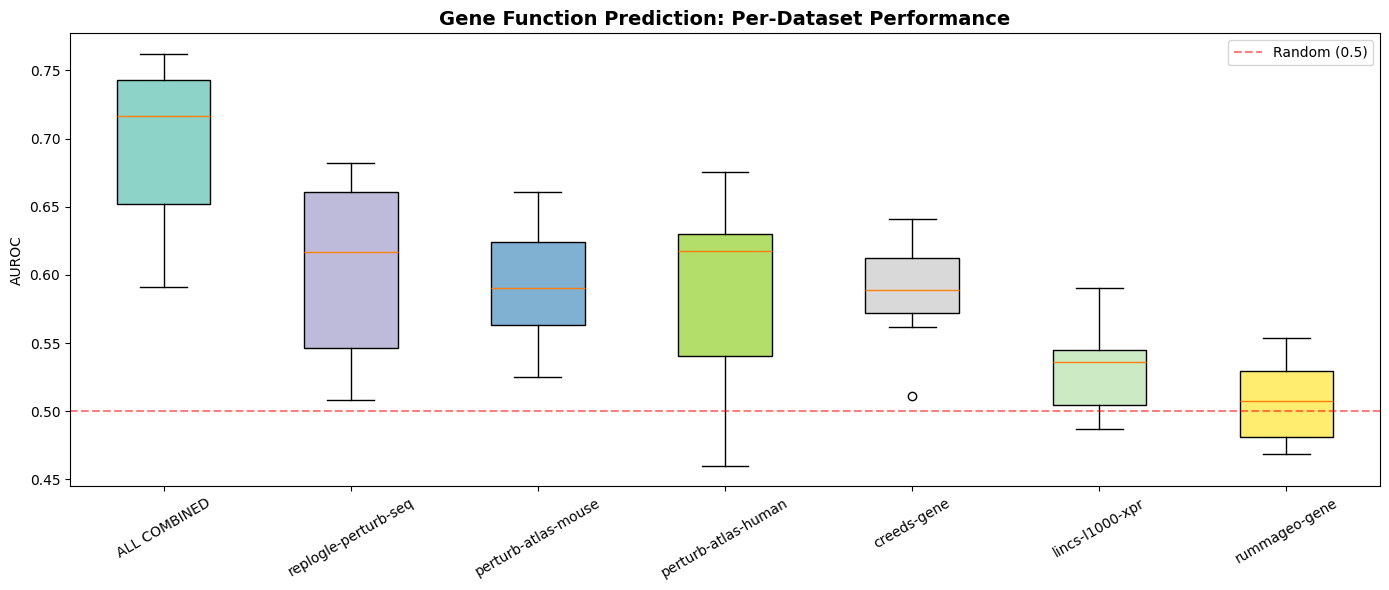

In [19]:
# Box plot comparing AUROC distributions per dataset
fig, ax = plt.subplots(figsize=(14, 6))

datasets_for_plot = summary_df["Dataset"].tolist()
box_data = []
for ds in datasets_for_plot:
    if ds == "ALL COMBINED":
        box_data.append(combined_df["auroc"].dropna().values)
    else:
        box_data.append(dataset_results[ds]["auroc"].dropna().values)

bp = ax.boxplot(box_data, labels=datasets_for_plot, patch_artist=True, vert=True)
colors = plt.cm.Set3(np.linspace(0, 1, len(datasets_for_plot)))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)

ax.axhline(y=0.5, color="red", linestyle="--", alpha=0.5, label="Random (0.5)")
ax.set_ylabel("AUROC")
ax.set_title("Gene Function Prediction: Per-Dataset Performance", fontsize=14, fontweight="bold")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR / "gene_function_per_dataset.png", dpi=150, bbox_inches="tight")
plt.show()